# Bayesian and variational inference: prediction, uncertainty, and approximation

## 1. Introduction and learning objectives

A fitted probability is not a distribution over unknown parameters. Bayesian inference combines a likelihood and prior, conditions on observations, and integrates over the resulting posterior when predicting. Its uncertainty is conditional on that model. Variational inference replaces a difficult posterior calculation with a restricted optimization problem; a well-optimized approximation can still miss important dependence and uncertainty.

Derive exact conjugate updates and posterior predictions, connect Gaussian MAP to the normalization of L2 objectives, implement and audit a Gaussian mean-field approximation, and check manual reparameterization gradients. Use exact small cases to distinguish model assumptions, numerical implementation, optimization stopping and approximation error. This prepares later generative modeling without introducing a framework or relying on reference functions from another notebook.

**Prerequisites:** Stage 00 probability, Jacobians, matrix calculus and numerical computing; Stage 01 objective normalization and experimental design; the [Stage 02 information/decision chapter](../02-classical-ml/probability-information-and-decisions.ipynb) for entropy and KL. The EM chapter's KL-bound identity is useful and is restated here. All work uses Python/NumPy/Matplotlib. No GPU, download or new dependency is required.

## 2. Prerequisites and mathematical foundations

For observations $D$, parameters $\theta$, proper prior $p(\theta)$ and likelihood $p(D\mid\theta)$,
$$p(\theta\mid D)=\frac{p(D\mid\theta)p(\theta)}{p(D)},\qquad p(D)=\int p(D\mid\theta)p(\theta)\,d\theta.$$
The denominator is the **evidence**, a probability or density of the observed data under the prior model. It is not the likelihood evaluated at a fitted parameter. A posterior predictive distribution is
$$p(y_{new}\mid D)=\int p(y_{new}\mid\theta)p(\theta\mid D)\,d\theta.$$
Integrate a shared unknown parameter once for a joint future batch; drawing a new independent parameter for each future observation generally gives a different joint distribution.

Parameter uncertainty and outcome noise are different. For a future scalar observation,
$$\operatorname{Var}(Y\mid D)=E[\operatorname{Var}(Y\mid\theta,D)\mid D]+\operatorname{Var}(E[Y\mid\theta,D]\mid D).$$
A posterior credible set has specified mass under the posterior model. It is not automatically a frequentist confidence procedure with nominal coverage at every fixed true parameter. Approximate sampling, an approximate posterior and a misspecified likelihood add separate limitations. A point estimate such as a posterior mean or MAP cannot summarize all these distinctions.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 03.04.01 — Identify the uncertainty and the probability space

**Type:** Conceptual · **Answer:** Markdown

Distinguish likelihood, evidence, parameter posterior, one-observation predictive and joint future-batch predictive distributions. Explain the difference between an interval for a parameter and one for a noisy future outcome. What does a posterior credible probability condition on, and what repeated-sampling claim does it not automatically establish?

**Expected outcome:** a generative/conditioning story and separate parameter, outcome, approximation and calibration claims.

**Your response to Exercise 03.04.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.01**

Conditioning on a fitted model does not prove that the model generated the observations. A shared random parameter can make future observations dependent after integration.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.01**

The likelihood is a function of parameters with the observed data fixed. Evidence integrates it against a prior. The posterior conditions that prior model on the data, and predictive distributions integrate future likelihoods against the posterior. A parameter interval concerns the unknown parameter; a predictive interval also includes future noise. Credible mass is conditional on the specified likelihood/prior and observations, plus numerical approximation if used. It is not a guarantee of nominal coverage for every fixed data-generating parameter, robustness to misspecification or accuracy of a variational approximation. Integrating one shared parameter for a batch also preserves dependence that separate plug-in predictions can discard.

</details>

## 3. Theoretical development and worked examples

### Beta–Bernoulli conjugacy and predictive dependence

Let $\theta\sim\operatorname{Beta}(a,b)$ with $a,b>0$, density $\theta^{a-1}(1-\theta)^{b-1}/B(a,b)$, and conditionally IID binary observations. After $h$ successes and $t$ failures, multiplying prior and likelihood gives $\operatorname{Beta}(A,B)$ with $A=a+h$, $B=b+t$. Define $S=A+B$. Its mean is $A/S$, variance $AB/[S^2(S+1)]$, and unique interior mode $(A-1)/(S-2)$ only when both shapes exceed one. Boundary and uniform cases require their own mode discussion.

An **ordered** binary sequence has likelihood $\theta^h(1-\theta)^t$, so its evidence is $B(A,B)/B(a,b)$. Observing only the count $h$ out of $h+t$ instead multiplies that evidence by $\binom{h+t}{h}$. These data events have the same posterior kernel but different probabilities. Use $\log B(a,b)=\log\Gamma(a)+\log\Gamma(b)-\log\Gamma(a+b)$ rather than raw factorial-like products.

For $K$ successes in a future batch of $m$ observations, integrate the binomial likelihood to obtain
$$p(K=k\mid D)=\binom mk\frac{B(A+k,B+m-k)}{B(A,B)},$$
$$E[K\mid D]=m\bar\theta,\quad \operatorname{Var}(K\mid D)=m\bar\theta(1-\bar\theta)\frac{S+m}{S+1},\qquad\bar\theta=A/S.$$
For distinct future binary observations, $\operatorname{Cov}(Y_1,Y_2\mid D)=\operatorname{Var}(\theta\mid D)$. This positive dependence explains the extra batch variance relative to a binomial plug-in model. For a single future binary observation, the variance is still $\bar\theta(1-\bar\theta)$; do not add parameter variance to that expression a second time.

**Hand case:** prior $\operatorname{Beta}(2,2)$ and $(h,t)=(3,1)$ give posterior $\operatorname{Beta}(5,3)$, mean $5/8$, variance $5/192$ and interior MAP $2/3$. Ordered-sequence evidence is $2/35$, count evidence $8/35$. The four-observation predictive probabilities for counts zero through four are $(1/22,5/33,3/11,7/22,7/33)$, with mean $2.5$ and variance $1.25$; the plug-in binomial variance is $.9375$.

### Gaussian conjugacy, prediction and the L2 scale

For $\theta\sim\mathcal N(\mu_0,v_0)$ and conditionally IID $y_i\sim\mathcal N(\theta,\sigma^2)$ with **known** noise variance, completing the square gives
$$v_n=(v_0^{-1}+n/\sigma^2)^{-1},\qquad\mu_n=v_n(\mu_0/v_0+\sum_i y_i/\sigma^2).$$
The posterior is $\mathcal N(\mu_n,v_n)$ and a future observation has distribution $\mathcal N(\mu_n,\sigma^2+v_n)$. Posterior mean and MAP coincide in this Gaussian model. Ignoring constants, the negative log posterior is $\sum_i(y_i-\theta)^2/(2\sigma^2)+(\theta-\mu_0)^2/(2v_0)$. Multiplication by $\sigma^2/n$ gives a mean half-squared-loss objective with L2 coefficient $\lambda=\sigma^2/(nv_0)$. A fixed prior therefore corresponds to a coefficient that changes with sample size under this averaging convention. Fixing $\lambda$ while changing $n$ implicitly changes that prior precision.

For $\mu_0=0,v_0=4,\sigma^2=1,y=(1,2)$, the posterior mean is $4/3$, variance $4/9$, predictive variance $13/9$ and mean-loss L2 coefficient $1/8$. No observation means no update; the coefficient is then not defined for a nonexistent mean training loss.

### Parameter coordinates and realized uncertainty

Density modes depend on coordinates. With $\phi=\log(\theta/(1-\theta))$, the transformed density is $p_\phi(\phi)=p_\theta(\theta)\theta(1-\theta)$. Its mode maps to $\theta=A/(A+B)$ for a Beta posterior, while the interior mode in $\theta$ is generally different. Posterior probabilities of transformed events remain consistent; density height and MAP are not coordinate-invariant summaries.

Also distinguish a realized posterior variance from its prior-predictive expectation. A surprising observation can increase variance for a particular posterior. Total variance instead gives
$$\operatorname{Var}(\theta)=E_D[\operatorname{Var}(\theta\mid D)]+\operatorname{Var}_D(E[\theta\mid D]),$$
under the prior joint model, so **expected** posterior variance cannot exceed prior variance. The Gaussian known-variance update above has a special data-independent variance reduction; it does not prove the corresponding claim for every Bayesian model and observation.

### Variational bounds and a Gaussian mean-field case

Write $\mathrm{KL}(q\|p)=E_q[\log(q/p)]$. For a finite divergence, $q$ must not assign positive probability to an event that the target rules out, and the relevant expectations must exist. An untransformed Gaussian on all of $\mathbb R$ therefore has infinite reverse KL to a Beta target supported on $(0,1)$; a suitable transformed family needs its Jacobian. For a density $q(\theta)$, define $\mathcal F(q)=E_q[\log p(D,\theta)-\log q(\theta)]$. When terms/support are well-defined,
$$\log p(D)-\mathcal F(q)=\mathrm{KL}(q\,\|\,p(\theta\mid D))\ge0.$$
Restricting $q$ to a factorized family can prevent equality even after correct optimization. A computable ELBO is not an available exact posterior-KL oracle when the evidence is unknown. The examples below deliberately use normalized Gaussian targets with known constants so this gap can be measured independently.

Let the target be $p=\mathcal N(\mu,\Sigma)$ in $d$ dimensions, precision $\Lambda=\Sigma^{-1}$, and approximation $q=\mathcal N(m,\operatorname{diag}(v))$. KL is a **single distributional divergence in nats**, not an observation- or dimension-averaged loss:
$$\mathrm{KL}(q\|p)=\tfrac12\left[\sum_j\Lambda_{jj}v_j+(m-\mu)^T\Lambda(m-\mu)-d+\log\det\Sigma-\sum_j\log v_j\right].$$
Differentiation gives $\Lambda(m-\mu)=0$ and $(\Lambda_{jj}-1/v_j)/2=0$. The quadratic mean term and each $\Lambda_{jj}v_j-\log v_j$ are strictly convex on their domains, so the unique global optimum within this diagonal Gaussian family has $m=\mu$ and $v_j=1/\Lambda_{jj}$. These are conditional-variance quantities, not generally the marginal variances $\Sigma_{jj}$. Coordinate ascent uses the most recently updated other means:
$$m_j\leftarrow\mu_j-\Lambda_{jj}^{-1}\sum_{\ell\ne j}\Lambda_{j\ell}(m_\ell-\mu_\ell),\qquad v_j\leftarrow1/\Lambda_{jj}.$$
These are instances of $\log q_j^*=E_{q_{-j}}\log p+\text{constant}$. Sequential coordinate updates improve the same bound; simultaneous stale updates are not automatically the same ascent procedure. Numerical gain stopping is not a guarantee of zero parameter gradient or zero approximation error.

For $\Sigma=\begin{pmatrix}1&.8\\.8&1\end{pmatrix}$, the optimum diagonal variances are both $.36$ while target marginal variances are one. The best factorized KL is $-\tfrac12\log(.36)\approx.51082562$, even with the exact target mean. A full Gaussian family can express this target exactly. This finite example demonstrates a restriction cost, not a universal theorem that all variational methods underestimate every uncertainty.

### Manual reparameterization gradients

Write $v_j=e^{2\ell_j}$, $\theta=m+e^\ell\odot\epsilon$, with IID $\epsilon\sim\mathcal N(0,I)$. For the fixed normalized Gaussian target, the Monte Carlo KL estimator is the average of $\log q(\theta)-\log p(\theta)$. Let $g(\theta)=\Lambda(\theta-\mu)$. Differentiating while holding the sampled $\epsilon$ fixed gives
$$\widehat\nabla_m\mathrm{KL}=\operatorname{mean}(g),\quad\widehat\nabla_{\ell}\mathrm{KL}=\operatorname{mean}(g\odot e^\ell\odot\epsilon)-1.$$
The exact expected derivatives are $\Lambda(m-\mu)$ and $\operatorname{diag}(\Lambda)\odot e^{2\ell}-1$. The sample average occurs once. Common random numbers are essential for a meaningful finite-difference check of this sample objective. In an unnormalized model, replacing $\log p$ with $\log p(D,\theta)$ gives negative ELBO, differing by a constant for this fixed target; it does not reveal the unknown exact KL value.

### Exercise 03.04.02 — Derive the conjugate posterior and joint predictive

**Type:** Mathematical · **Answer:** Markdown

Derive the Beta posterior, ordered versus count evidence, posterior moments and beta-binomial predictive probabilities. Use total variance and conditional independence to derive future-count variance and the covariance of two future binary observations. Explain why independently drawing a parameter for each future observation changes the joint predictive.

**Expected outcome:** correct normalizing constants and combinatorial factors, a shared-parameter batch model and no double-counted one-step variance.

**Your response to Exercise 03.04.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.02**

Integrating $\theta^k(1-\theta)^{m-k}$ against a Beta posterior gives a ratio of beta functions. Off-diagonal future covariances equal the variance of their conditional mean.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.02**

Multiplication adds success/failure exponents, giving shapes $A=a+h,B=b+t$. Normalization yields the beta-function evidence ratio; only a count event includes the binomial multiplicity. Integrating a future binomial gives the stated beta-binomial mass. Conditional means are $m\theta$ and conditional variances $m\theta(1-\theta)$, so total variance gives $m\bar\theta(1-\bar\theta)+m(m-1)\operatorname{Var}(\theta)$, equivalent to the formula above. Two future outcomes have covariance $\operatorname{Var}(\theta)$ because their conditional covariance is zero. For one observation the two variance terms sum to $\bar\theta(1-\bar\theta)$. New independent parameters per observation remove the shared mixing dependence and produce a different batch model.

</details>

### Exercise 03.04.03 — Reproduce the conjugate hand cases

**Type:** Numerical · **Answer:** Markdown

Calculate the Beta hand case's posterior mean/variance/MAP, ordered/count evidence and all five four-observation predictive probabilities. Verify predictive mean/variance and compare with the plug-in binomial. Calculate the Gaussian hand case's posterior and predictive variances and L2 coefficient.

**Expected outcome:** the listed rational values, predictive variance $1.25$ versus $.9375$, and Gaussian $(\mu_n,v_n,\sigma^2+v_n,\lambda)=(4/3,4/9,13/9,1/8)$.

**Your response to Exercise 03.04.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.03**

For integer shapes, $B(a,b)=(a-1)!(b-1)!/(a+b-1)!$. Check that the five probabilities sum to one before computing moments.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.03**

Posterior Beta shapes are five and three. Mean is $5/8$, variance $15/(64\cdot9)=5/192$, and interior mode $4/6=2/3$. The ordered evidence ratio is $(1/105)/(1/6)=2/35$, multiplied by four for the count event. The future masses are $(1/22,5/33,3/11,7/22,7/33)$; their moments give $2.5$ and $1.25$. The plug-in variance is $4(5/8)(3/8)=.9375$. Gaussian posterior precision is $1/4+2=9/4$ and information numerator three, giving mean $4/3$ and variance $4/9$; add noise one for prediction. Scaling the negative log posterior by $1/2$ gives L2 coefficient $1/8$ under the mean-loss convention.

</details>

### Exercise 03.04.04 — Audit MAP coordinates and regularization scaling

**Type:** Mathematical · **Answer:** Markdown

Derive the Beta density under the logit coordinate and compare its mapped mode with the original interior MAP for the hand case. Then derive the Gaussian mean-loss L2 coefficient and explain what keeping it fixed while doubling sample size does to the implied prior variance.

**Expected outcome:** mapped logit-density mode $5/8$ versus original MAP $2/3$, consistent event probabilities, and explicit sample-size scaling of the prior.

**Your response to Exercise 03.04.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.04**

Include the Jacobian $d\theta/d\phi=\theta(1-\theta)$. Multiplying an objective by a positive constant preserves its minimizer but changes reported gradient scales.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.04**

Multiplication by the Jacobian makes the transformed density proportional to $\theta^A(1-\theta)^B$, maximized at $A/(A+B)$ when mapped back from the logit coordinate. The original interior density mode is $(A-1)/(A+B-2)$. This is a coordinate dependence of density modes, not inconsistent probabilities for transformed events. For the Gaussian objective, multiplying by $\sigma^2/n$ yields mean half squared loss plus $\sigma^2/(2nv_0)$ times squared displacement from the prior mean. Thus $\lambda=\sigma^2/(nv_0)$. With noise and $\lambda$ fixed, doubling $n$ halves the implied prior variance; it is not a fixed-prior comparison.

</details>

## 4. Guided exercises

### Exercise 03.04.05 — Implement Beta inference in the log domain

**Type:** Programming · **Answer:** Code

Implement `log_beta`, `beta_log_density`, `beta_update` and `beta_predictive` with finite positive shapes. Preserve endpoint density limits, including uniform and singular cases, without $0\log0$ NaNs. Validate nonnegative integer observation counts with total at most 10,000 and future batch size at most 200. Return ordered evidence separately, an interior MAP only when uniquely interior, predictive masses and analytic moments. Do not silently renormalize an inaccurate probability table.

**Expected outcome:** the hand rational values, normalized bounded predictive tables, sequential/batch equivalence and visible arithmetic-range failures.

In [ ]:
# Your code for Exercise 03.04.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.05**

Use log gamma for beta-function ratios. At a shape equal to one, its log-coordinate term contributes zero even at the endpoint.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.05**

These helpers are local to this chapter. Interior MAP is explicitly named; a missing interior value is not a claim that boundary or nonunique modes do not exist. The arithmetic is checked on the declared small workloads. Log-domain calculation avoids raw-product overflow, but does not make arbitrarily large-shape cancellation exact. A saturated mean, vanished variance or nonfinite normalization is reported instead of fabricated certainty.

~~~python
import math

def inference_positive(value, name):
    array = np.asarray(value,dtype=float)
    if isinstance(value,(bool,np.bool_)) or array.ndim != 0 or not np.isfinite(array) or array <= 0:
        raise ValueError(name+' must be a finite positive scalar')
    return float(array)

def beta_shapes(a, b):
    a = inference_positive(a,'a'); b = inference_positive(b,'b')
    with np.errstate(over='raise',invalid='raise'):
        total = float(np.add(a,b))
    return a,b,total

def log_beta(a, b):
    a,b,_ = beta_shapes(a,b)
    try:
        value = math.lgamma(a)+math.lgamma(b)-math.lgamma(a+b)
    except (OverflowError,ValueError) as error:
        raise FloatingPointError('log beta exceeds the arithmetic range') from error
    if not np.isfinite(value):
        raise FloatingPointError('nonfinite log beta')
    return value

def beta_log_density(theta, a, b):
    a,b,_ = beta_shapes(a,b); theta = np.asarray(theta,dtype=float)
    if not np.isfinite(theta).all() or np.any((theta < 0)|(theta > 1)):
        raise ValueError('theta must lie in [0, 1]')
    result = np.full(theta.shape,-log_beta(a,b))
    with np.errstate(divide='ignore',over='raise',invalid='raise'):
        if a != 1:
            result = result+(a-1)*np.log(theta)
        if b != 1:
            result = result+(b-1)*np.log1p(-theta)
    return result

def beta_moments(a, b):
    a,b,total = beta_shapes(a,b)
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        mean = a/total; variance = (a/total)*(b/total)/(total+1)
    if not 0 < mean < 1 or not np.isfinite(variance) or variance <= 0:
        raise FloatingPointError('Beta moments saturated or underflowed')
    return mean,variance

def beta_update(a, b, successes, failures):
    a,b,_ = beta_shapes(a,b)
    counts = (successes,failures)
    if any(isinstance(c,(bool,np.bool_)) or not isinstance(c,(int,np.integer)) or c < 0 for c in counts) or int(successes)+int(failures) > 10000:
        raise ValueError('nonnegative integer counts with total <=10000 required')
    with np.errstate(over='raise',invalid='raise'):
        A,B = float(np.add(a,successes)),float(np.add(b,failures))
    mean,variance = beta_moments(A,B)
    return dict(a=A,b=B,mean=mean,variance=variance,
        interior_map=(A-1)/(A+B-2) if A > 1 and B > 1 else None,
        log_ordered_evidence=log_beta(A,B)-log_beta(a,b))

def beta_predictive(a, b, m):
    a,b,total = beta_shapes(a,b)
    if isinstance(m,(bool,np.bool_)) or not isinstance(m,(int,np.integer)) or not 0 <= m <= 200:
        raise ValueError('integer future batch size 0..200 required')
    base = log_beta(a,b); log_mass = np.array([
        math.lgamma(m+1)-math.lgamma(k+1)-math.lgamma(m-k+1)+log_beta(a+k,b+m-k)-base
        for k in range(m+1)])
    if not np.isfinite(log_mass).all():
        raise FloatingPointError('nonfinite predictive log mass')
    mean,variance_theta = beta_moments(a,b)
    with np.errstate(over='raise',invalid='raise'):
        plugin = m*mean*(1-mean)
        variance = plugin+m*(m-1)*variance_theta
    return dict(log_mass=log_mass,mass=np.exp(log_mass),mean=m*mean,variance=variance,
                plugin_variance=plugin,parameter_variance=variance_theta)
~~~

</details>

### Exercise 03.04.06 — Complete the square and preserve predictive noise

**Type:** Programming · **Answer:** Code

Implement `gaussian_mean_update` for a proper Gaussian prior, known positive observation-noise variance and a finite one-dimensional data vector of length 0–10,000. Return posterior mean/variance, predictive variance and the implied mean-loss L2 coefficient when observations exist. Check the hand case and an independent negative-log-posterior derivative.

**Expected outcome:** precision-weighted estimates, prior recovery with no data, correct noise addition and no silently changed prior when sample size changes.

In [ ]:
# Your code for Exercise 03.04.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.06**

The posterior mean is a convex combination of the prior mean and sample mean. Its predictive variance adds parameter variance to known outcome-noise variance.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.06**

This uses the positive-scalar helper. The likelihood assumes known noise and a shared constant mean, not an arbitrary regression or unknown-noise model. The coefficient is returned only for a nonempty mean training loss. Finite inputs with unrepresentable precision, summaries or predictive variance raise arithmetic errors.

~~~python
def gaussian_mean_update(y, prior_mean=0., prior_variance=4., noise_variance=1.):
    y = np.asarray(y,dtype=float); prior_mean = np.asarray(prior_mean,dtype=float)
    if y.ndim != 1 or len(y) > 10000 or not np.isfinite(y).all() or prior_mean.ndim != 0 or not np.isfinite(prior_mean):
        raise ValueError('finite 1D observations and scalar prior mean required')
    v0 = inference_positive(prior_variance,'prior variance')
    noise = inference_positive(noise_variance,'noise variance'); n = len(y)
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        prior_precision = np.divide(1.,v0); data_precision = np.divide(n,noise)
        precision = prior_precision+data_precision; variance = np.divide(1.,precision)
        mean = (prior_precision/precision)*prior_mean
        if n:
            mean = mean+(data_precision/precision)*y.mean()
        predictive_variance = noise+variance
        penalty = float(np.divide(np.divide(noise,v0),n)) if n else None
    if not np.isfinite(mean) or not np.isfinite(predictive_variance) or variance <= 0 or (n and (not np.isfinite(penalty) or penalty <= 0)):
        raise FloatingPointError('unrepresentable Gaussian posterior')
    return dict(mean=float(mean),variance=float(variance),predictive_variance=float(predictive_variance),
                mean_loss_l2=penalty,n_samples=n)
~~~

</details>

## 5. Implementation challenges

The remaining calculations use vectors of length $d\le8$, covariance/precision matrices $(d,d)$ and reparameterization samples $(s,d)$. KL values refer to a fixed Gaussian target distribution, not an average data loss. The target is deliberately tractable so errors in variational optimization and family restriction can be separated. It does not turn exact posterior normalization into a generally available operation.

### Exercise 03.04.07 — Measure Gaussian KL and the best factorized approximation

**Type:** Programming · **Answer:** Code

Implement `gaussian_target`, `gaussian_kl` and `meanfield_closed_form` for finite vectors of length 1–8 and positive definite symmetric covariances. Use Cholesky factors/solves for precision and log determinants. Check arbitrary Gaussian KL against an independent two-dimensional scalar formula. Derive the factorized optimum and compare its variances with true marginals for correlation $.8$.

**Expected outcome:** correct direction/sign/constants of a non-averaged KL, exact self-KL within roundoff and a measurable restricted-family gap.

In [ ]:
# Your code for Exercise 03.04.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.07**

The general KL trace uses the target precision and the approximation covariance. Swapping those objects changes the divergence direction.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.07**

These local helpers accept covariances symmetric within the stated roundoff tolerance and use their symmetric part. They reject invalid or unrepresentable models. Tiny negative self-KL from rounding is reported, not silently clipped into apparent exactness. The diagonal optimum follows from differentiation with respect to the mean and each positive variance. A full Gaussian family contains the target, while the diagonal family generally does not.

~~~python
def gaussian_target(mean, covariance):
    mean = np.asarray(mean,dtype=float); covariance = np.asarray(covariance,dtype=float)
    if mean.ndim != 1 or not 1 <= len(mean) <= 8 or not np.isfinite(mean).all():
        raise ValueError('finite mean vector with width 1..8 required')
    d = len(mean)
    if covariance.shape != (d,d) or not np.isfinite(covariance).all() or not np.allclose(covariance,covariance.T,rtol=1e-10,atol=1e-12):
        raise ValueError('finite symmetric covariance with shape (d, d) required')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        covariance = .5*covariance+.5*covariance.T
        factor = np.linalg.cholesky(covariance)
        precision = np.linalg.solve(factor.T,np.linalg.solve(factor,np.eye(d)))
        logdet = float(2*np.log(np.diag(factor)).sum())
    if not np.isfinite(precision).all() or not np.isfinite(logdet):
        raise FloatingPointError('unrepresentable Gaussian precision or log determinant')
    return dict(mean=mean.copy(),covariance=covariance.copy(),precision=precision,logdet=logdet)

def gaussian_kl(mean_q, covariance_q, target):
    q = gaussian_target(mean_q,covariance_q); d = len(q['mean'])
    if target['mean'].shape != (d,):
        raise ValueError('Gaussian dimensions must match')
    with np.errstate(over='raise',invalid='raise'):
        difference = q['mean']-target['mean']
        value = .5*(np.trace(target['precision']@q['covariance'])
            +difference@target['precision']@difference-d+target['logdet']-q['logdet'])
    if not np.isfinite(value):
        raise FloatingPointError('nonfinite Gaussian KL')
    return float(value)

def meanfield_closed_form(target):
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        variance = 1/np.diag(target['precision'])
    if not np.isfinite(variance).all() or np.any(variance <= 0):
        raise FloatingPointError('unrepresentable mean-field variance')
    mean = target['mean'].copy()
    return dict(mean=mean,variance=variance,kl=gaussian_kl(mean,np.diag(variance),target))
~~~

</details>

### Exercise 03.04.08 — Optimize one variational coordinate at a time

**Type:** Programming · **Answer:** Code

Implement `fit_meanfield_gaussian` with copied initial means/positive variances, 1–200 sequential sweeps and a finite nonnegative relative KL-gain tolerance. Update using current other-coordinate means, retain every coordinate KL and full-sweep mean, and check nonincrease within roundoff. Return the actual tolerance/budget status and a mean-gradient diagnostic. Compare the finite result with the closed optimum without using that optimum to replace the updates.

**Expected outcome:** auditable coordinate ascent, consistent returned parameters, a deliberate budget-limited case and nonzero family error after correct optimization.

In [ ]:
# Your code for Exercise 03.04.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.08**

The complete conditional precision for coordinate $j$ is $\Lambda_{jj}$. Use updated preceding coordinates within the same sweep, not a stale parallel snapshot.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.08**

This depends on the Gaussian helpers. The target is prepared by `gaussian_target`, not an arbitrary serialized schema. Exact KL is available only because this teaching target is normalized and tractable. The stopping rule records small observed objective gain; it does not promise a particular parameter-error tolerance or eliminate the diagonal-family gap. Caller arrays are copied and all coordinate updates use one fixed target.

~~~python
def fit_meanfield_gaussian(target, initial_mean=None, initial_variance=None, max_sweeps=100, tol=1e-9):
    d = len(target['mean'])
    if isinstance(max_sweeps,(bool,np.bool_)) or not isinstance(max_sweeps,(int,np.integer)) or not 1 <= max_sweeps <= 200 or not np.isfinite(tol) or tol < 0:
        raise ValueError('sweep budget 1..200 and finite nonnegative tolerance required')
    mean = np.zeros(d) if initial_mean is None else np.array(initial_mean,dtype=float,copy=True)
    variance = np.ones(d) if initial_variance is None else np.array(initial_variance,dtype=float,copy=True)
    if mean.shape != (d,) or variance.shape != (d,) or not np.isfinite(mean).all() or not np.isfinite(variance).all() or np.any(variance <= 0):
        raise ValueError('finite initial vectors and positive variances required')
    coordinate_kl = [gaussian_kl(mean,np.diag(variance),target)]; sweep_kl = coordinate_kl.copy()
    mean_history = [mean.copy()]; status = 'budget'; precision = target['precision']
    for sweep in range(1,max_sweeps+1):
        previous = sweep_kl[-1]
        for j in range(d):
            other = np.arange(d) != j
            with np.errstate(over='raise',invalid='raise',divide='raise'):
                mean[j] = target['mean'][j]-precision[j,other]@(mean[other]-target['mean'][other])/precision[j,j]
                variance[j] = 1/precision[j,j]
            value = gaussian_kl(mean,np.diag(variance),target)
            if value > coordinate_kl[-1]+1e-10*max(1.,abs(coordinate_kl[-1])):
                raise FloatingPointError('coordinate KL increased beyond roundoff tolerance')
            coordinate_kl.append(value)
        sweep_kl.append(value); mean_history.append(mean.copy()); gain = previous-value
        if gain <= tol*(1+abs(previous)):
            status = 'tolerance'; break
    with np.errstate(over='raise',invalid='raise'):
        gradient_norm = float(np.hypot.reduce(precision@(mean-target['mean'])))
    return dict(mean=mean,variance=variance,kl=value,status=status,sweeps=sweep,last_gain=gain,
        coordinate_kl=np.array(coordinate_kl),sweep_kl=np.array(sweep_kl),mean_history=np.array(mean_history),
        mean_gradient_norm=gradient_norm)
~~~

</details>

### Exercise 03.04.09 — Check exact and reparameterized KL gradients manually

**Type:** Programming · **Answer:** Code

Implement `diagonal_kl_gradients` and `reparameterized_kl` with mean/log-standard-deviation vectors and a supplied finite noise array of shape $(s,d)$, $1\le s\le20000$. Validate representable positive variances. Return objective and mean/log-scale gradients; the sampled estimator also reports its IID standard-error estimate when $s>1$. Compare both gradients with independent finite differences, freezing noise for the sample objective. Use a deterministic zero-mean/identity-second-moment probe to check this quadratic target exactly, without treating that probe as IID Monte Carlo.

**Expected outcome:** correct scale derivatives and averaging, fixed-noise checks and a clear distinction between exact expectation, sampled estimate and estimated sampling error.

In [ ]:
# Your code for Exercise 03.04.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.09**

Along the reparameterization, $\log q=-\tfrac d2\log(2\pi)-\sum\ell_j-\tfrac12\|\epsilon\|^2$. Its total location derivative is zero and its log-scale derivative contributes minus one.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.09**

This depends on the Gaussian helpers. The target is fixed. Samples are supplied rather than hidden inside a finite-difference objective, so the caller controls reproducibility. A sampled KL estimate can be negative through noise even though exact KL is nonnegative; no clipping hides that variation. The standard-error formula assumes IID standard-normal noise and is not a statistical guarantee for a deterministic moment probe or dependent draws.

~~~python
def diagonal_variational_state(mean, log_std, target):
    mean = np.asarray(mean,dtype=float); log_std = np.asarray(log_std,dtype=float)
    d = len(target['mean'])
    if mean.shape != (d,) or log_std.shape != (d,) or not np.isfinite(mean).all() or not np.isfinite(log_std).all():
        raise ValueError('finite mean/log-std vectors matching the target required')
    with np.errstate(over='raise',invalid='raise'):
        std = np.exp(log_std); variance = std*std
    if not np.isfinite(variance).all() or np.any(variance <= 0):
        raise FloatingPointError('variational variance underflow or overflow')
    return mean,log_std,std,variance

def diagonal_kl_gradients(mean, log_std, target):
    mean,log_std,std,variance = diagonal_variational_state(mean,log_std,target)
    with np.errstate(over='raise',invalid='raise'):
        mean_gradient = target['precision']@(mean-target['mean'])
        scale_gradient = np.diag(target['precision'])*variance-1
    return dict(kl=gaussian_kl(mean,np.diag(variance),target),mean_gradient=mean_gradient,
                log_std_gradient=scale_gradient)

def reparameterized_kl(mean, log_std, epsilon, target):
    mean,log_std,std,variance = diagonal_variational_state(mean,log_std,target)
    epsilon = np.asarray(epsilon,dtype=float); d = len(mean)
    if epsilon.ndim != 2 or epsilon.shape[1] != d or not 1 <= len(epsilon) <= 20000 or not np.isfinite(epsilon).all():
        raise ValueError('finite (s, d) noise with 1..20000 rows required')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        samples = mean+std*epsilon; difference = samples-target['mean']
        sensitivity = difference@target['precision'].T
        log_p = -.5*(d*np.log(2*np.pi)+target['logdet']+np.sum(difference*sensitivity,axis=1))
        log_q = -.5*(d*np.log(2*np.pi)+2*log_std.sum()+np.sum(epsilon*epsilon,axis=1))
        pointwise = log_q-log_p
        error = float(pointwise.std(ddof=1)/np.sqrt(len(epsilon))) if len(epsilon) > 1 else None
        value = float(pointwise.mean()); mean_gradient = sensitivity.mean(axis=0)
        scale_gradient = (sensitivity*std*epsilon).mean(axis=0)-1
    return dict(kl_estimate=value,mean_gradient=mean_gradient,log_std_gradient=scale_gradient,
                iid_standard_error=error,n_samples=len(epsilon))
~~~

</details>

## 6. Experiments and visualizations

The default demonstration uses **given hand formulas**, with no general inference implementation. It compares two normalized Beta densities, the known future-count masses with a binomial plug-in, and exact 95%-mass contours for the given two-dimensional Gaussian target and its narrower diagonal approximation. A two-standard-deviation ellipse would not have 95% mass in two dimensions; the radius below is $\sqrt{-2\log(.05)}$.

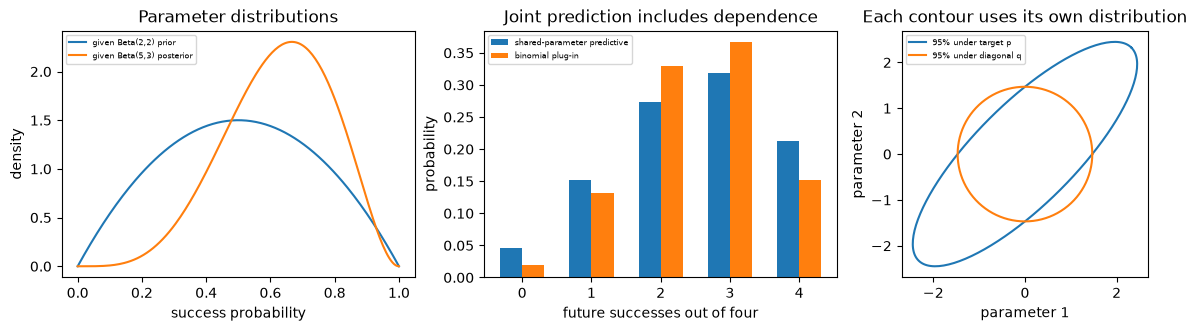

In [2]:
fig,axes = plt.subplots(1,3,figsize=(12,3.2),layout='constrained')
given_theta = np.linspace(0,1,201)
axes[0].plot(given_theta,6*given_theta*(1-given_theta),label='given Beta(2,2) prior')
axes[0].plot(given_theta,105*given_theta**4*(1-given_theta)**2,label='given Beta(5,3) posterior')
axes[0].set(xlabel='success probability',ylabel='density',title='Parameter distributions'); axes[0].legend(fontsize=6)
given_counts = np.arange(5); given_predictive = np.array([1/22,5/33,3/11,7/22,7/33])
given_plugin = np.array([1,4,6,4,1])*(5/8)**given_counts*(3/8)**(4-given_counts)
axes[1].bar(given_counts-.16,given_predictive,width=.32,label='shared-parameter predictive')
axes[1].bar(given_counts+.16,given_plugin,width=.32,label='binomial plug-in')
axes[1].set(xlabel='future successes out of four',ylabel='probability',title='Joint prediction includes dependence'); axes[1].legend(fontsize=6)
given_angles = np.linspace(0,2*np.pi,201); given_circle = np.column_stack([np.cos(given_angles),np.sin(given_angles)])
given_rotation = np.array([[1.,-1.],[1.,1.]])/np.sqrt(2); given_radius = np.sqrt(-2*np.log(.05))
given_target_contour = (given_circle*np.sqrt([1.8,.2]))@given_rotation.T*given_radius
given_q_contour = given_circle*.6*given_radius
axes[2].plot(*given_target_contour.T,label='95% under target p')
axes[2].plot(*given_q_contour.T,label='95% under diagonal q')
axes[2].set(xlabel='parameter 1',ylabel='parameter 2',title='Each contour uses its own distribution',aspect='equal'); axes[2].legend(fontsize=6)
plt.show()

### Exercise 03.04.10 — Measure prior sensitivity and shared-parameter prediction

**Type:** Experimental · **Answer:** Code

Compare priors Beta$(1,1)$, Beta$(2,8)$ and Beta$(20,20)$ after counts $(3,1)$ and $(60,20)$. Report posterior means/variances and approximate 95% intervals from 4,000 posterior draws per case, seed 290. Plot the actual densities. Separately simulate 12,000 future four-observation batches from posterior Beta$(5,3)$, seed 291: draw one shared parameter per batch, then its binomial count. Compare empirical masses/moments with the analytic predictive and plug-in variance. Record elapsed time and explain which uncertainty each calculation measures.

**Expected outcome:** reproducible sensitivity and predictive comparisons, explicit Monte Carlo approximation and no assumption that a posterior interval has universal repeated-data coverage.

In [ ]:
# Your code for Exercise 03.04.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.10**

The same observed success fraction does not make the small/large samples equally informative. Resampling an independent parameter for every future trial would remove the dependence under investigation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.10**

This uses the Beta helpers. Counts and priors are predeclared rather than chosen to maximize a reused evaluation outcome. The quantiles are finite-sample estimates of posterior intervals; they are not exact numerical inverses of a Beta CDF. Future-batch simulation is a check of the specified posterior predictive model, not evidence that this prior/likelihood generated real data. The empirical count variance should be interpreted with its Monte Carlo variation, and its difference from a plug-in model has an exact shared-parameter explanation.

~~~python
from time import perf_counter

prior_rng = np.random.default_rng(290); prior_results = []; prior_started = perf_counter()
fig,axes = plt.subplots(1,3,figsize=(12,3.2),layout='constrained')
prior_grid = np.linspace(0,1,301)
for axis,(h,t) in zip(axes[:2],((3,1),(60,20))):
    for a,b in ((1.,1.),(2.,8.),(20.,20.)):
        posterior = beta_update(a,b,h,t)
        draws = prior_rng.beta(posterior['a'],posterior['b'],size=4000)
        interval = np.quantile(draws,[.025,.975])
        record = dict(prior=(a,b),counts=(h,t),mean=posterior['mean'],variance=posterior['variance'],
                      estimated_interval=interval.tolist(),draws=len(draws))
        prior_results.append(record); print('prior sensitivity',record)
        axis.plot(prior_grid,np.exp(beta_log_density(prior_grid,posterior['a'],posterior['b'])),label=str((a,b)))
    axis.set(title=str(h+t)+' observations',xlabel='success probability',ylabel='Posterior density')
    axis.legend(title='Prior shapes',fontsize=6,title_fontsize=7)
predictive_rng = np.random.default_rng(291)
batch_parameters = predictive_rng.beta(5.,3.,size=12000)
future_counts = predictive_rng.binomial(4,batch_parameters)
predictive_exact = beta_predictive(5.,3.,4)
predictive_empirical = np.bincount(future_counts,minlength=5)/len(future_counts)
print('future counts',dict(empirical_masses=predictive_empirical.tolist(),
    analytic_masses=predictive_exact['mass'].tolist(),empirical_mean=float(future_counts.mean()),
    empirical_variance=float(future_counts.var()),analytic_variance=predictive_exact['variance'],
    plugin_variance=predictive_exact['plugin_variance']))
axes[2].bar(np.arange(5),predictive_exact['mass'],alpha=.6,label='analytic predictive')
axes[2].plot(np.arange(5),predictive_empirical,'o',label='12,000 simulated batches')
axes[2].set(title='Shared-parameter future counts',xlabel='successes out of four',ylabel='Probability')
axes[2].legend(fontsize=6); plt.show()
print('prior/predictive study seconds',perf_counter()-prior_started)
~~~

</details>

### Exercise 03.04.11 — Separate optimizer stopping from variational family error

**Type:** Experimental · **Answer:** Code

Prepare a Gaussian target with mean $(.5,-.25)$ and covariance $\begin{pmatrix}1&.8\\.8&1\end{pmatrix}$. Start mean-field coordinates at mean $(2,-2)$ and variances $(1,1)$, budget 100 sweeps, tolerance $10^{-9}$. Report the actual trace/status, mean-gradient norm, fitted variances and KL gap to the closed diagonal optimum. Draw 12,000 target samples and 12,000 fitted-$q$ samples with seed 292. Estimate target mass inside the fitted $q$'s 95% ellipse and compare with mass under $q$ and the target's own 95% ellipse. Plot actual traces and contours.

**Expected outcome:** a correctly optimized restricted approximation with a nonzero family gap and a distribution-specific mass comparison, rather than an implied frequentist coverage claim.

In [ ]:
# Your code for Exercise 03.04.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.11**

In two dimensions, a Gaussian's squared Mahalanobis radius has CDF $1-e^{-r^2/2}$. The 95% threshold is $-2\log(.05)$ under that Gaussian, not under every other distribution.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.11**

This uses the Gaussian KL, closed optimum and coordinate fitter. The exact target is a tractable audit case; an unknown posterior would not generally provide its true KL or target samples so easily. The known diagonal optimum has variances $.36$ and KL about $.51082562$. A small optimization gap does not remove that restriction cost. Mass estimates use IID samples from their named distributions and have binomial Monte Carlo error. They do not assess repeated datasets or establish calibration for an arbitrary statistical model.

~~~python
from time import perf_counter

meanfield_target = gaussian_target([.5,-.25],[[1.,.8],[.8,1.]])
meanfield_started = perf_counter()
meanfield_fit = fit_meanfield_gaussian(meanfield_target,initial_mean=[2.,-2.],
    initial_variance=[1.,1.],max_sweeps=100,tol=1e-9)
meanfield_optimum = meanfield_closed_form(meanfield_target)
print('mean-field fit',dict(status=meanfield_fit['status'],sweeps=meanfield_fit['sweeps'],
    mean=meanfield_fit['mean'].tolist(),variance=meanfield_fit['variance'].tolist(),kl=meanfield_fit['kl'],
    optimum_kl=meanfield_optimum['kl'],optimization_gap=meanfield_fit['kl']-meanfield_optimum['kl'],
    mean_gradient_norm=meanfield_fit['mean_gradient_norm'],seconds=perf_counter()-meanfield_started))
mass_rng = np.random.default_rng(292); mass_draws = 12000; radius_squared = -2*np.log(.05)
mass_p = mass_rng.multivariate_normal(meanfield_target['mean'],meanfield_target['covariance'],size=mass_draws)
mass_q = meanfield_fit['mean']+mass_rng.normal(size=(mass_draws,2))*np.sqrt(meanfield_fit['variance'])
q_radius_p = np.sum((mass_p-meanfield_fit['mean'])**2/meanfield_fit['variance'],axis=1)
q_radius_q = np.sum((mass_q-meanfield_fit['mean'])**2/meanfield_fit['variance'],axis=1)
centered_p = mass_p-meanfield_target['mean']
p_radius_p = np.sum(centered_p*(centered_p@meanfield_target['precision']),axis=1)
mass_results = {}
for name,indicator in [('p_mass_of_q_region',q_radius_p <= radius_squared),
                       ('q_mass_of_q_region',q_radius_q <= radius_squared),
                       ('p_mass_of_p_region',p_radius_p <= radius_squared)]:
    probability = float(indicator.mean())
    mass_results[name] = dict(estimate=probability,MC_standard_error=np.sqrt(probability*(1-probability)/mass_draws))
print('named distribution masses',mass_results)
fig,axes = plt.subplots(1,2,figsize=(9.5,3.3),layout='constrained')
axes[0].plot(meanfield_fit['coordinate_kl'],label='actual coordinate KL')
axes[0].axhline(meanfield_optimum['kl'],color='black',linestyle='--',label='best diagonal KL')
axes[0].set(xlabel='coordinate update',ylabel='KL(q || p), nats',title='Optimization stops above zero',yscale='log')
axes[0].set_yticks([.5,1,2,5,10],labels=['0.5','1','2','5','10']); axes[0].minorticks_off(); axes[0].legend(fontsize=7)
contour_angles = np.linspace(0,2*np.pi,201); contour_circle = np.column_stack([np.cos(contour_angles),np.sin(contour_angles)])
contour_values,contour_vectors = np.linalg.eigh(meanfield_target['covariance'])
contour_p = (contour_circle*np.sqrt(contour_values))@contour_vectors.T*np.sqrt(radius_squared)+meanfield_target['mean']
contour_q = contour_circle*np.sqrt(meanfield_fit['variance'])*np.sqrt(radius_squared)+meanfield_fit['mean']
axes[1].scatter(*mass_p[:300].T,s=5,alpha=.2,label='target samples')
axes[1].plot(*contour_p.T,label='95% under p'); axes[1].plot(*contour_q.T,label='95% under q')
axes[1].set(xlabel='parameter 1',ylabel='parameter 2',title='Mass statements name a distribution',aspect='equal'); axes[1].legend(fontsize=6)
plt.show()
~~~

</details>

### Exercise 03.04.12 — Measure stochastic-gradient variation against an exact oracle

**Type:** Experimental · **Answer:** Code

For the preceding fixed Gaussian target, use variational mean $(.1,.3)$ and standard deviations $(.9,.7)$. Compare exact KL/gradients with reparameterized estimates using 128, 512 and 2,048 IID noise rows over eight predeclared child seeds, root 293. Use prefixes of each trial's largest draw to pair sample sizes. Report every estimate and gradient error norm, and plot the observed mean/range of errors. Do not assert that each larger sample must improve a particular realization or that eight trials form a calibrated interval.

**Expected outcome:** a bounded numerical study separating exact expectation, one noisy estimate and observed replicate variability.

In [ ]:
# Your code for Exercise 03.04.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.12**

Finite differences should use one frozen noise array. This experiment instead varies draws deliberately to measure sampling variation at fixed variational parameters.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.12**

This depends on the exact/sample gradient helpers and the target from the preceding experiment. Larger IID samples reduce variance under the stated assumptions, but realized error norms need not decrease monotonically. The plotted min/max across eight trials is descriptive, not a confidence interval. The exact Gaussian objective is a diagnostic oracle for this example; most complex posterior targets do not expose it directly.

~~~python
gradient_mean = np.array([.1,.3]); gradient_log_std = np.log([.9,.7])
gradient_exact = diagonal_kl_gradients(gradient_mean,gradient_log_std,meanfield_target)
gradient_truth = np.r_[gradient_exact['mean_gradient'],gradient_exact['log_std_gradient']]
gradient_records = {size:[] for size in (128,512,2048)}
for trial,child in enumerate(np.random.SeedSequence(293).spawn(8)):
    gradient_rng = np.random.default_rng(child); noise = gradient_rng.normal(size=(2048,2))
    for size in gradient_records:
        estimate = reparameterized_kl(gradient_mean,gradient_log_std,noise[:size],meanfield_target)
        packed = np.r_[estimate['mean_gradient'],estimate['log_std_gradient']]
        gradient_records[size].append(dict(trial=trial,kl=estimate['kl_estimate'],
            KL_MC_standard_error=estimate['iid_standard_error'],gradient_error=float(np.linalg.norm(packed-gradient_truth))))
print('exact gradient oracle',gradient_exact)
for size,records in gradient_records.items():
    print('gradient samples',size,records)
fig,axes = plt.subplots(1,2,figsize=(9,3),layout='constrained')
sizes = list(gradient_records)
error_groups = [[record['gradient_error'] for record in gradient_records[size]] for size in sizes]
means = np.array([np.mean(group) for group in error_groups])
low = np.array([min(group) for group in error_groups]); high = np.array([max(group) for group in error_groups])
axes[0].errorbar(sizes,means,yerr=[means-low,high-means],marker='o',capsize=4)
axes[0].set(xscale='log',yscale='log',xlabel='IID noise rows',ylabel='Gradient error norm',title='Eight-trial mean and observed range')
for size in sizes:
    axes[1].scatter(np.full(8,size),[record['kl'] for record in gradient_records[size]],s=15)
axes[1].axhline(gradient_exact['kl'],color='black',linestyle='--',label='exact KL')
axes[1].set(xscale='log',xlabel='IID noise rows',ylabel='Sampled KL estimate',title='Fixed parameters, changing samples'); axes[1].legend(fontsize=7)
for axis in axes:
    axis.set_xticks(sizes,labels=[str(size) for size in sizes]); axis.set_xticks([],minor=True)
plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Bounded primary-source studies

Read [Stanford CS228 Bayesian Learning, Setup and Conjugate Priors/Beta Distribution](https://ermongroup.github.io/cs228-notes/learning/bayesian/) after deriving the Beta update. Verify its conjugacy/moment formulas and test a blanket variance-decrease interpretation against one surprising observation. The local study distinguishes realized and expected uncertainty; it does not validate unrelated applications on the page.

Read [Blei, Kucukelbir and McAuliffe, §§2.2–2.4, equations (13), (15), (18)](https://arxiv.org/html/1601.00670v9) after implementing KL and coordinate updates. Translate the mean-field update into the fixed Gaussian case and measure its optimum restriction gap. This original small reproduction concerns those equations and the correlated-Gaussian interpretation, not the paper's full mixture experiments or a general theorem about all variational uncertainty.

### Exercise 03.04.13 — Audit a realized-variance claim with exact conjugacy

**Type:** Experimental · **Answer:** Code

For prior Beta$(10,1)$, calculate the posterior after one surprising failure and compare variances. Also calculate the posterior after one success. Average the two posterior variances using the prior predictive outcome probabilities, then add the variance of the posterior means. Compare with prior variance and the selected reading's broad decrease interpretation. Report which claim is refuted and which expectation identity holds.

**Expected outcome:** realized variance increases from $10/1452$ to $20/1872$, while expected posterior variance plus variance of posterior means equals prior variance.

In [ ]:
# Your code for Exercise 03.04.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.13**

The predictive success probability is $10/11$. The two posterior means are $11/12$ and $10/12$, not the same value.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.13**

This uses the Beta update/moment helpers, with independent rational verification supplied in the numerical checks. A failure shifts mass away from a highly concentrated boundary prior and increases the realized variance: $20/1872>10/1452$. Success gives variance $11/1872$. Their prior-predictive weighted average is smaller than prior variance. The missing amount is the variance of the two possible posterior means, exactly as total variance requires. This original finite counterexample rejects an unconditional statement about every realized update; it does not reject Bayes' rule, conjugacy or expected uncertainty reduction under the prior joint model.

~~~python
variance_mean,variance_prior = beta_moments(10.,1.)
variance_success = beta_update(10.,1.,1,0); variance_failure = beta_update(10.,1.,0,1)
expected_posterior_variance = variance_mean*variance_success['variance']+(1-variance_mean)*variance_failure['variance']
posterior_mean_variance = variance_mean*(variance_success['mean']-variance_mean)**2 \
    +(1-variance_mean)*(variance_failure['mean']-variance_mean)**2
print('variance audit',dict(prior=variance_prior,after_failure=variance_failure['variance'],
    after_success=variance_success['variance'],expected_posterior_variance=expected_posterior_variance,
    variance_of_posterior_means=posterior_mean_variance,
    total_variance_residual=variance_prior-expected_posterior_variance-posterior_mean_variance))
assert variance_failure['variance'] > variance_prior
assert expected_posterior_variance < variance_prior
assert abs(variance_prior-expected_posterior_variance-posterior_mean_variance) < 1e-15
~~~

</details>

### Exercise 03.04.14 — Review uncertainty and convergence claims separately

**Type:** Critical · **Answer:** Markdown

A report says its posterior is narrow, its coordinate optimizer has stopped, its Monte Carlo gradient is small, and its approximate credible region has 95% mass under $q$. What evidence is still missing before claiming accurate parameter uncertainty, a globally optimized general posterior, calibrated prediction or 95% target/frequentist coverage? Include prior/likelihood assumptions, family restriction, finite samples and prior selection using the same data.

**Expected outcome:** supported conditional statements and separate missing model, approximation, optimization and calibration evidence.

**Your response to Exercise 03.04.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.14**

One approximation can be exactly optimized and still be too restrictive. A region with specified mass under $q$ need not have that mass under the target $p$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.14**

Narrowness is a property of the specified posterior or approximation, conditional on a prior/likelihood and data. A gain threshold reports one optimizer diagnostic, and a small noisy gradient requires its sampling error and objective to be understood. Mean-field restrictions can leave a nonzero exact-target KL even at their optimum. A 95% region under $q$ has no automatic 95% target-posterior mass, and posterior mass is different again from repeated-data coverage at a fixed parameter. Predictive noise and shared-parameter dependence must be integrated correctly. Repeatedly choosing priors or model assumptions after inspecting the same outcomes changes the inference protocol. Independent checks, sensitivity analysis and task-specific evaluation support distinct claims; none is replaced by a stopping flag or a single narrow interval.

</details>

## 8. Review questions and knowledge checks

### Exercise 03.04.15 — Compare parameter, single-outcome and batch uncertainty

**Type:** Numerical · **Answer:** Markdown

For posterior $\operatorname{Beta}(5,3)$, calculate parameter variance, one-observation predictive variance, covariance of two future outcomes and variance of a four-observation future count. Compare the joint probability of two successes with the product of the marginal success probabilities. Explain why these observations are conditionally independent yet predictively dependent.

**Expected outcome:** $5/192$, $15/64$, $5/192$, $1.25$, and joint probability $5/12$ versus product $25/64$.

**Your response to Exercise 03.04.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.15**

Use $E[\theta^2]=A(A+1)/(S(S+1))$ and subtract $(E\theta)^2$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.15**

Parameter variance is $5/192$. A single binary observation has variance $(5/8)(3/8)=15/64$. Two outcomes share a parameter, so their covariance is $E\theta^2-(E\theta)^2=5/12-25/64=5/192$. Four-outcome variance is $4(15/64)+4\cdot3(5/192)=1.25$. Conditioning on a fixed $\theta$ makes their likelihood factorize. Integrating a common uncertain $\theta$ couples the outcomes; multiplying separately integrated marginals discards this dependence. Adding parameter variance again to the single-outcome Bernoulli variance would double count it.

</details>

### Exercise 03.04.16 — Present an inference mastery gate

**Type:** Conceptual · **Answer:** Markdown

Explain posterior/evidence/predictive distinctions, conjugacy, coordinate-dependent MAP, mean-loss regularization scaling, the ELBO gap, mean-field restriction and manual sample gradients. Present independent exact/scalar/finite-difference checks and measured prior/predictive/approximation experiments. Name an uncertainty claim the evidence still cannot support.

**Expected outcome:** explain/implement/verify/evaluate evidence that keeps model, numerical, optimization and approximation errors separate.

**Your response to Exercise 03.04.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.04.16**

Pair each claim with the object actually checked: a probability identity, a derivative, an optimizer trace, a distributional approximation or a predictive experiment.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.04.16**

A complete submission derives conjugate/predictive quantities and bound identities, implements the local inference and coordinate/sample-gradient calculations, and records priors, seeds, normalization and stopping budgets. Rational probabilities, square completion, independent Gaussian KL formulas and fixed-noise finite differences verify specific contracts. Measured prior sensitivity, shared-parameter prediction, restricted-family error and stochastic-gradient variation evaluate concrete procedures. The evidence supports those calculations and conditional comparisons. It does not prove arbitrary model correctness, universally accurate uncertainty, exact recovery of an intractable posterior or frequentist coverage merely from a posterior/approximation mass statement.

</details>

## 9. Summary and next learning steps

Bayesian prediction integrates parameter uncertainty under an explicit model. Conjugate cases supply exact audit targets and expose differences between estimates, evidence, predictive noise and dependence. Variational bounds and manual reparameterization gradients extend the computational view, while a known Gaussian target separates optimizer progress from approximation error.

Before advancing, submit the derivations, manual helpers, independent checks, measured sensitivity/predictive/mean-field studies and bounded source audits. Next: density estimation and anomaly detection, where predictive density, score geometry, thresholds, contamination and distribution shift meet. Later generative models revisit these bound and sampling ideas with learned architectures. Return to the [stage guide](README.md) or [learning path](../../README.md); unfinished units remain planned.